# Imports

In [27]:
from langchain.agents import create_agent
from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.output_parsers import StrOutputParser
from langmem import create_search_memory_tool, create_manage_memory_tool
from langgraph.store.memory import InMemoryStore
from dotenv import load_dotenv
import warnings
import os

warnings.filterwarnings("ignore")

load_dotenv()
api_key = os.getenv("API_KEY")

In [35]:
SYSTEM_PROMPT = """
You are AI-assistant for recommending foods, and exercise for diet-routine. You have listed tools,

<TOOLS>
1) manage_memory tool - Tool to save, update and delete user memories and facts.
2) search_memory tool - Tool to search the existing memories and user preferences.
</TOOLS>

<RULES>
1) If user explicitly says the preferences and facts store in memory by manage_memory.
2) If user asks about previous history and facts retrieve from search_memory.
3) Before answering to user queries recall the stored facts.
4) Never claim something was saved unless tool succeed.
</RULES>

<CONSTRAINTS>
Make a tool call to access past memories and facts.
</CONSTRAINTS>
"""

In [54]:
# Memory-tool Setup:
user_id = "user_123"
manage_tool = create_manage_memory_tool(namespace=(user_id, "memories"))
search_tool = create_search_memory_tool(namespace=(user_id, "memories"))

# Groq Model:
model = ChatGroq(
    model='openai/gpt-oss-120b',
    api_key=api_key,
    temperature=0.3
)

In [55]:
#Store:
embeddings_model = HuggingFaceEmbeddings(
    model='sentence-transformers/all-MiniLM-L6-v2',
    model_kwargs = {"device": "cpu"}
)
store = InMemoryStore(
    index={
        "dims" : 384,
        "embed" : embeddings_model,
        'fields' : ['content']
    }
)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2182.69it/s]


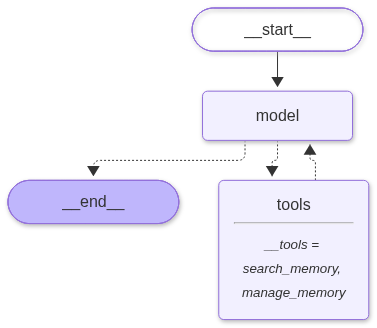

In [56]:
agent = create_agent(
    model=model,
    tools=[search_tool, manage_tool],
    store=store,
    system_prompt=SYSTEM_PROMPT,
)
agent

In [60]:
config = {
    "configurable" :{
        "user_id" : user_id
    }
}

question_to_check = "Tell about me that you know?"
question = "Remember i love calisthenics and meat like mutton, fish and chicken"
response = agent.invoke({"messages" : [{"role" : "user", "content" : question_to_check}]},config=config)

In [61]:
# Parser:
parser = StrOutputParser()

response = parser.invoke(response['messages'][-1].content)
print(response)

Here’s what I have on file about you so far:

- **Fitness:** You enjoy **calisthenics** as your primary form of exercise.  
- **Food preferences:** You like **meat**, especially **mutton, fish, and chicken**.

If there’s anything else you’d like me to note—dietary restrictions, favorite workouts, goals, or any other preferences—just let me know and I’ll add it to your profile!
